---
title: "L7-01 · Define the learning task"
short_title: "Define the learning task"
subtitle: "A method answers the question its target and data make answerable: prediction accuracy, an identified causal effect, and a quantum resource saving are different claims with different evidence, and a quantum processor changes cost and function class, never what the data identify."
description: "Specify a research task by its data access, target and evidence, and separate three questions that are often merged: prediction, causal identification, and quantum resource advantage."
tags: [level-7, coursebook]
---

(lesson-l7-01)=

:::{div}
:class: qcai-meta
![Level 7 icon](../../_static/icons/qicon-level-7.svg) **Level 7 · Doctoral & postdoctoral** · about 100 minutes  
**Big idea.** A method answers the question its target and data make answerable: prediction accuracy, an identified causal effect, and a quantum resource saving are different claims with different evidence, and a quantum processor changes cost and function class, never what the data identify.  
**Before this lesson.** [L4-10](#lesson-l4-10), [L6-10](#lesson-l6-10)  
**Lab.** [Confounding and intervention](../../labs/03-causal-inference.ipynb)
:::

## What you will be able to do

- Write a task specification that names the data access, the target (risk, estimand or cost), the assumptions and the resource budget, and classify a published claim as a prediction, causal or resource claim.
- Prove that the squared-loss risk minimizer is $E[Y \mid X]$ and compute, for a given structural model, how far its contrast is from the interventional effect.
- Prove that no estimator, classical or quantum, that receives only samples of an observational distribution can be consistent for an effect that distribution does not identify.
- State what evidence each kind of claim needs, including what a quantum resource comparison must hold fixed.

## Why this matters

A preprint trains a variational quantum classifier on hospital records, reports 0.91 test accuracy against 0.88 for a classical network, and concludes that the treatment variable "has a strong causal influence" and that "quantum models learn causal structure more efficiently." Three different claims hide in that sentence. One is about prediction on a fixed distribution. One is about what would happen under an intervention. One is about a quantum resource. Each can be true while the others are false, and none of the evidence offered addresses the second or the third.

Research in quantum machine learning, causal inference and quantum causal modeling uses overlapping words for different tasks [@qml; @costa; @bareinboim]. This lesson gives you a way to pin a task down before choosing a method: state the data access, the target, the assumptions and the resource budget. It then proves two short results that do most of the sorting: the best predictor estimates a conditional expectation, not an effect, and no processor, quantum or classical, can extract a quantity the data do not identify.

:::{dropdown} Key terms

**Task specification**
: The data access, the target quantity, the loss or error criterion, the assumptions and the resource budget, stated before a method is chosen.

**Prediction risk**
: $R(f) = E[\ell(f(X), Y)]$ under the distribution the predictor will be used on; its minimizer for squared loss is $E[Y \mid X]$.

**Causal estimand**
: An interventional quantity such as $\tau = E[Y \mid do(A=1)] - E[Y \mid do(A=0)]$, defined by a causal model and an intervention [@pearlcausality; @bareinboim].

**Identification**
: The property that the target takes the same value in every model of the assumed class that agrees with the available data; developed formally in [L7-05](#lesson-l7-05).

**Resource claim**
: A statement that one class of algorithms reaches a stated accuracy with less of a named resource (samples, queries, gates, qubits, time) than another, under the same access model.

**Data access model**
: How information reaches the learner: classical records, copies of quantum states, or calls to a physical process, possibly with interventions [@qml; @costa].

:::


In [1]:
import sys, pathlib, subprocess
here = pathlib.Path.cwd()
root = next((p for p in [here, *here.parents] if (p / "qcai").is_dir()), None)
if root is None:  # for example on Google Colab: fetch the course's small teaching package
    root = pathlib.Path("quantum-causal-ai")
    if not root.exists():
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/pozapas/quantum-causal-ai.git", str(root)], check=True)
    root = root.resolve()
sys.path.insert(0, str(root))
from qcai.viz import show as _show, show_mpl as _show_mpl
from qcai.lessonfigs import l7_01 as _lessonfigs

## Three questions in one sentence

:::{prf:definition} Task specification
:label: def-l7-01-task
A **learning task** is a tuple $(\mathcal{D}, T, \mathcal{M}, \mathcal{E}, B)$: the **data access** $\mathcal{D}$ (what the learner receives: i.i.d. classical records from a distribution $P$, copies of a quantum state, or calls to a process, with or without interventions), the **target** $T$ (a predictor's risk, an estimand $\tau(M)$ of an unknown model $M$, or a cost at fixed accuracy), the **model class** $\mathcal{M}$ of mechanisms considered possible, the **error criterion** $\mathcal{E}$ (loss, accuracy $\epsilon$ and failure probability $\delta$), and the **budget** $B$ (samples, queries, shots, gates, qubits, time).
:::

:::{figure} ../../_static/animations/l7_01_three_questions.mp4
:alt: A decision tree with one root question and three branches: prediction, intervention effect and quantum resource saving, each with its formula and a short list of the evidence it needs.
:width: 100%

Sort a claim by what it delivers. Each branch has its own target and its own evidence; a study can make all three claims, but evidence for one is not evidence for another.
:::

:::{dropdown} What the animation shows
The root box asks what the study claims to deliver. Three branches grow from it. The first, a prediction, shows the risk $R(f) = E[\ell(f(X), Y)]$ and lists its evidence: held-out risk with error bars, on the same distribution as use, with distribution shift as a separate claim. The second, an intervention effect, shows $\tau = E[Y \mid do(A=1)] - E[Y \mid do(A=0)]$ and lists: estimand stated first, identification assumptions, estimator and sensitivity analysis. The third, a quantum resource saving, compares the quantum cost at accuracy $\epsilon$ with the minimum classical cost and lists: access model stated, tuned classical baselines, and all costs including shots, gates and data loading. A closing line says that one study can make all three claims and each needs its own evidence.
:::

```{mermaid}
graph TD
  Q["What is the requested output?"] --> P["label or value for new inputs"]
  Q --> C["effect of an intervention"]
  Q --> R["cost at fixed accuracy"]
  P --> P1["target: risk R(f)"]
  P1 --> P2["evidence: held-out risk, CI, same distribution"]
  C --> C1["target: estimand tau"]
  C1 --> C2["evidence: identification + estimator + sensitivity"]
  R --> R1["target: samples, queries, gates, time"]
  R1 --> R2["evidence: access model + strong baselines + full ledger"]
```

*The decision tree as a checklist. Mermaid boxes cannot hold formulas; the animation and the definitions give the exact targets.*


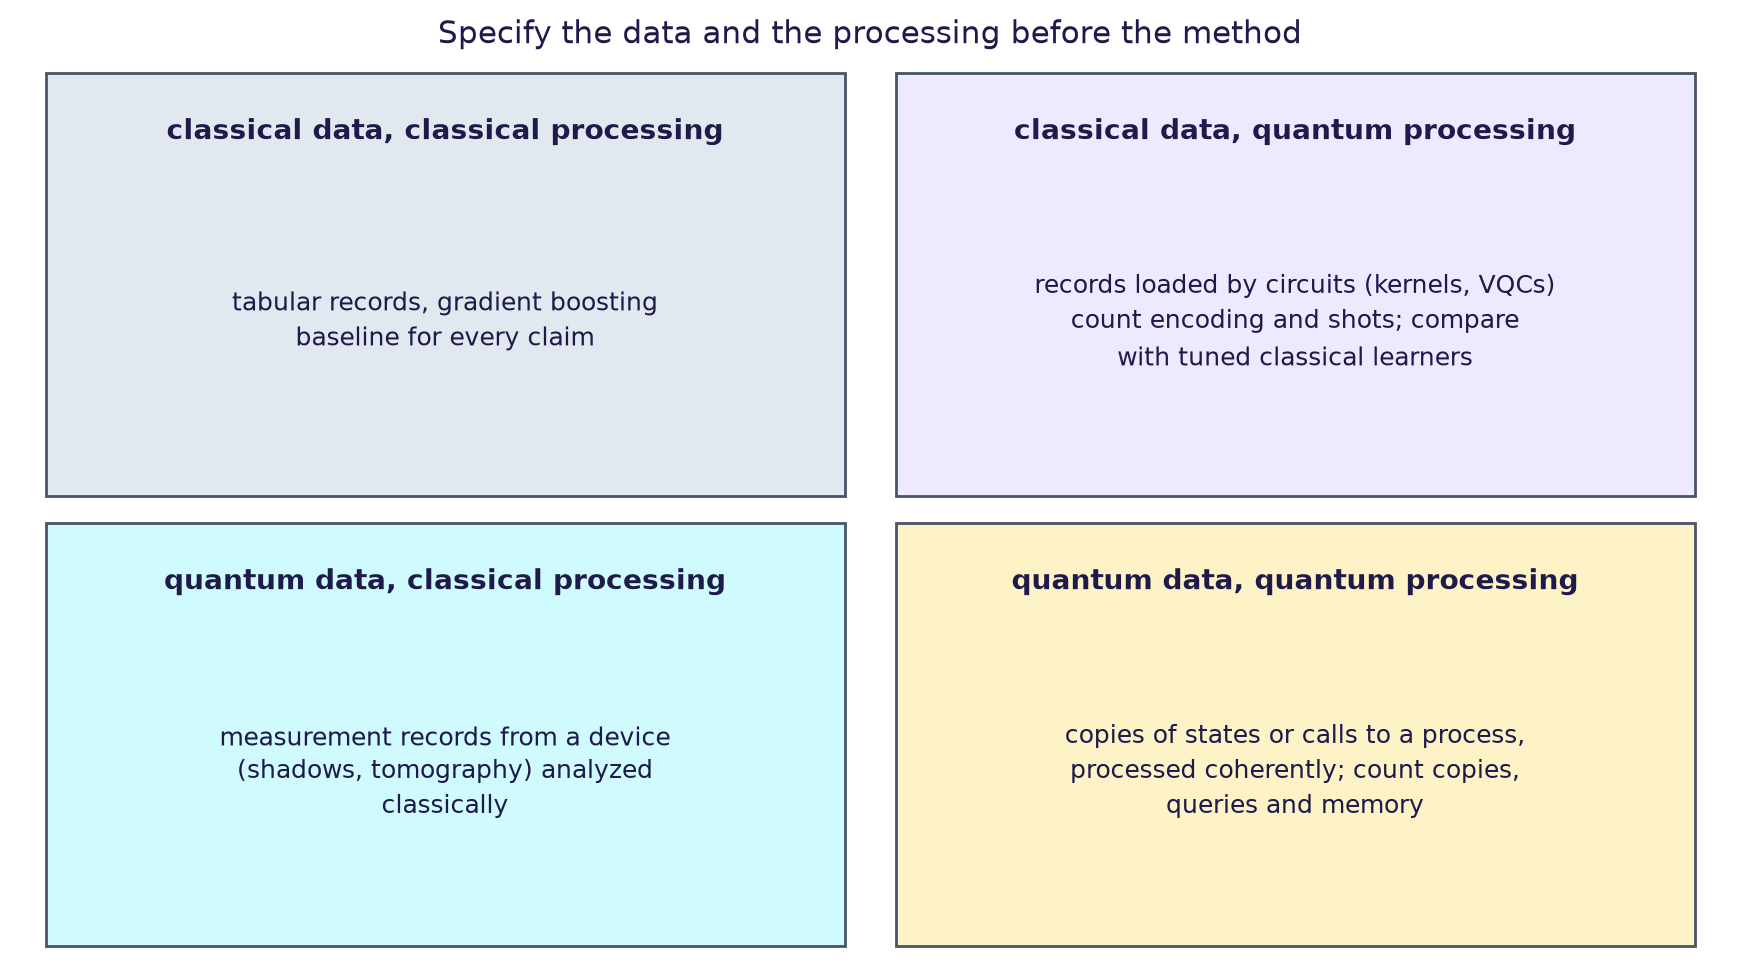

In [2]:
_show_mpl(_lessonfigs.access_grid())

*Data and processing are separate choices. Each cell names a typical setting and what its resource count must include; quantum processing of classical data, the top-right cell, is where most advantage claims are made and where data loading is easiest to forget.*

The prediction and causal targets live on different layers of the causal hierarchy: associational quantities are functions of the observational distribution, interventional ones require a model of what changes under $do(\cdot)$, and counterfactual ones require more still [@pearlcausality; @bareinboim]. Data from a lower layer do not in general determine quantities on a higher layer. The quantum resource question is orthogonal to both: it asks how expensive it is to compute or estimate a well-defined target, whatever layer it lives on.

## What a perfect predictor estimates

:::{prf:theorem} The squared-loss risk minimizer is the conditional mean
:label: thm-l7-01-bayes
Let $E[Y^2] < \infty$ and $m(x) = E[Y \mid X = x]$. For every measurable $f$ with $E[f(X)^2] < \infty$,
:::

$$
E\big[(f(X) - Y)^2\big] = E\big[(f(X) - m(X))^2\big] + E\big[\operatorname{Var}(Y \mid X)\big]
$$ (eq-l7-01-decomp)

:::{prf:proof}
Write $f(X) - Y = (f(X) - m(X)) + (m(X) - Y)$ and expand the square. The cross term is $2E[(f(X) - m(X))(m(X) - Y)] = 2E[(f(X) - m(X))\,E[m(X) - Y \mid X]] = 0$ by the tower property, because $E[Y \mid X] = m(X)$. The last term is $E[(m(X) - Y)^2] = E[\operatorname{Var}(Y \mid X)]$. So the risk is minimized exactly by $f = m$ (almost surely), with minimal value $E[\operatorname{Var}(Y \mid X)]$, the Bayes risk [@mml].
:::

Any learner that drives its excess risk to zero, whether a neural network, a kernel machine or a variational quantum circuit, therefore converges to $m(x) = E[Y \mid X = x]$, an associational quantity. Whether $m(1) - m(0)$ equals the effect $\tau$ is a property of the causal model, not of the learner. The course engine's model `science.causal()` makes this concrete: $Z \sim \text{Bernoulli}(0.5)$, $P(X{=}1 \mid Z) = 0.2 + 0.6Z$, and $P(Y{=}1 \mid X, Z) = 0.1 + 0.2X + cZ$ with $c = 0.5$.

:::{prf:example} Contrast 0.5, effect 0.2
:label: ex-l7-01-scm
Bayes' rule gives $P(Z{=}1 \mid X{=}1) = 0.4/0.5 = 0.8$ and $P(Z{=}1 \mid X{=}0) = 0.1/0.5 = 0.2$. So $m(1) = 0.3 + 0.5\cdot 0.8 = 0.7$ and $m(0) = 0.1 + 0.5\cdot 0.2 = 0.2$: the observed contrast is $0.5$. Under $do(X = x)$ the edge $Z \to X$ is cut and $Z$ keeps its marginal, so $E[Y \mid do(X=1)] = 0.55$ and $E[Y \mid do(X=0)] = 0.1 + 0.5\cdot 0.5 = 0.35$: the effect is $\tau = 0.2$. For a general strength $c$ the observed contrast is $0.2 + c(0.8 - 0.2) = 0.2 + 0.6c$, while $\tau = 0.2$ for every $c$. The Bayes risk is $0.5(0.7\cdot 0.3) + 0.5(0.2\cdot 0.8) = 0.185$.
:::

:::{figure} ../../_static/animations/l7_01_prediction_vs_intervention.mp4
:alt: A causal graph Z to X, Z to Y, X to Y with bar charts: conditional means 0.7 and 0.2, then after cutting the arrow into X, interventional means 0.55 and 0.35; then a plot of the observed contrast rising with the confounding strength while the effect stays at 0.2.
:width: 100%

The perfect predictor sees $E[Y \mid X{=}1] - E[Y \mid X{=}0] = 0.5$. Graph surgery on $X$ gives the effect $0.55 - 0.35 = 0.2$. Sweeping the strength $c$ of $Z \to Y$ moves the observed contrast along $0.2 + 0.6c$ and leaves the effect alone.
:::

:::{dropdown} What the animation shows
A causal graph shows $Z$ pointing to $X$ and to $Y$, and $X$ pointing to $Y$, with the mechanisms $P(X{=}1 \mid Z) = 0.2 + 0.6Z$ and $P(Y{=}1 \mid X, Z) = 0.1 + 0.2X + cZ$. Two blue bars show $E[Y \mid X=1] = 0.7$ and $E[Y \mid X=0] = 0.2$, an observed contrast of $0.5$. The arrow from $Z$ to $X$ turns red and is removed, marked $do(X)$. Two violet bars show $E[Y \mid do(X=1)] = 0.55$ and $0.35$, so $\tau = 0.55 - 0.35 = 0.2$. The bars are replaced by a plot against the confounding strength $c$ from 0 to 0.5: a flat violet line at $\tau = 0.2$ and a blue point that traces the line $\text{observed} = 0.2 + 0.6c$ with a live readout, ending at 0.5. A note says only $c = 0$, no confounding path, makes them agree.
:::


In [3]:
_show(_lessonfigs.confounding_explorer())

**Explore.** Change the strength $c$ of the path $Z \to Y$. The observed contrast moves; the contrast adjusted for $Z$ and the true effect stay at 0.2.

:::{dropdown} What the figure shows
The first panel shows three bars at the chosen $c$: the observed contrast $0.2 + 0.6c$, the backdoor-adjusted contrast and the true effect, both 0.2. The second panel plots the observed contrast against $c$ from 0 to 0.5 as a rising line from 0.2 to 0.5, with a dashed line for the true effect at 0.2 and a marker at the chosen $c$.
:::

## No processor recovers what the data do not identify

Hide $Z$. Model A is the confounded model above. Model B has no confounder: $P(X{=}1) = 0.5$ and $P(Y{=}1 \mid X) = 0.2 + 0.5X$. Both produce the same joint table, $P(X{=}1, Y{=}1) = 0.35$, $P(X{=}1, Y{=}0) = 0.15$, $P(X{=}0, Y{=}1) = 0.10$, $P(X{=}0, Y{=}0) = 0.40$, hence the same best predictor and the same Bayes risk $0.185$. Their effects are $\tau_A = 0.2$ and $\tau_B = 0.5$.

:::{figure} ../../_static/animations/l7_01_same_data.mp4
:alt: Two causal graphs, one with a hidden confounder and one without, both feeding the same two-by-two probability table; below them the effects 0.2 and 0.5.
:width: 100%

Two models, one table. Any procedure that sees only $P(X, Y)$ gives the same answer for both, so it must be wrong for at least one of them.
:::

:::{dropdown} What the animation shows
On the left, model A has a dashed hidden node $Z$ pointing to $X$ and $Y$, and $X$ pointing to $Y$. On the right, model B has only $X$ pointing to $Y$. Arrows from both lead to one table $P(X, Y)$ with entries 0.35 and 0.15 in the row $X = 1$ and 0.10 and 0.40 in the row $X = 0$. Below the table: the best predictor is $E[Y \mid X]$ with risk 0.185 in both models. Then the effects appear under each graph, $\tau_A = 0.2$ and $\tau_B = 0.5$, and a line states that no estimator using $P(X, Y)$ alone can be right in both models. A final line lists the remedies: measure $Z$ for a backdoor adjustment, randomize $X$, or add a justified assumption.
:::

:::{prf:proposition} No consistent estimator without identification
:label: prop-l7-01-noid
Let $M_1, M_2$ be models in the assumed class with the same observational distribution $P$ but $\tau(M_1) \ne \tau(M_2)$. Let $\hat\tau_n$ be any estimator that is a measurable function of $n$ i.i.d. samples from $P$ and of independent internal randomness, including the outcomes of any quantum computation whose input is those samples. Then $\hat\tau_n$ cannot converge in probability to $\tau(M)$ under both $M = M_1$ and $M = M_2$.
:::

:::{prf:proof}
The joint law of the samples and the internal randomness is the same under $M_1$ and $M_2$, because both models induce $P$ and the internal randomness does not depend on the model. Hence $\hat\tau_n$ has the same distribution $Q_n$ under both. If $\hat\tau_n \to \tau(M_1)$ in probability under $M_1$, then $Q_n$ concentrates at $\tau(M_1)$, so under $M_2$ it also converges to $\tau(M_1) \ne \tau(M_2)$. A quantum computation that takes classical samples as input and returns measurement outcomes is a randomized map of the samples, so it is covered.
:::

:::{important} What a quantum processor can and cannot change
It can change the function class a learner searches, the cost of evaluating it, and possibly the samples needed to reach a given risk. It cannot change which targets the data identify. Identification must be argued from the data access and the model class: measure the confounder, run the intervention, or state an assumption that rules one model out. When the data themselves are quantum (copies of states, calls to a channel, chosen instruments), the same logic applies with the operational equivalence class of the accessible experiments in place of $P$ [@costa]; [L7-05](#lesson-l7-05) develops it.
:::

Simulate model A with 400000 records, fit the most flexible predictor of $Y$ from $X$, and compare its contrast with the backdoor-adjusted estimate. Then simulate model B and compare the joint tables. Nothing quantum is needed to see the problem, and nothing quantum would solve it.


In [4]:
import numpy as np
from qcai import science as s

# Model A: Z -> X, Z -> Y, X -> Y  (science.causal defaults: P(X=1|Z) = 0.2 + 0.6 Z, P(Y=1|X,Z) = 0.1 + 0.2 X + 0.5 Z)
rng = np.random.default_rng(1)
n = 400_000
Z = rng.random(n) < 0.5
X = rng.random(n) < np.where(Z, 0.8, 0.2)
Y = rng.random(n) < 0.1 + 0.2 * X + 0.5 * Z

train, test = slice(0, n // 2), slice(n // 2, n)
# The most flexible predictor of Y from X alone: the cell means (the Bayes predictor for squared loss)
m = {x: Y[train][X[train] == x].mean() for x in (0, 1)}
pred = np.where(X[test], m[1], m[0])
risk = np.mean((pred - Y[test]) ** 2)
print(f"fitted E[Y|X=1] = {m[1]:.3f}, E[Y|X=0] = {m[0]:.3f}, held-out squared-error risk = {risk:.4f} (Bayes risk 0.185)")
print(f"observed contrast m(1) - m(0) = {m[1] - m[0]:.3f}")

# Backdoor adjustment uses Z: sum_z P(z) (E[Y|X=1,z] - E[Y|X=0,z])
adj = sum(np.mean(Z == z) * (Y[(X == 1) & (Z == z)].mean() - Y[(X == 0) & (Z == z)].mean()) for z in (False, True))
print(f"backdoor-adjusted contrast = {adj:.3f}; engine's true effect = {s.causal()['ate']:.3f}")

# Model B: no confounder, P(X=1) = 0.5, P(Y=1|X) = 0.2 + 0.5 X.  Same joint P(X, Y), effect 0.5.
XB = rng.random(n) < 0.5
YB = rng.random(n) < 0.2 + 0.5 * XB
for x in (1, 0):
    for y in (1, 0):
        print(f"P(X={x}, Y={y}):  model A {np.mean((X == x) & (Y == y)):.3f}   model B {np.mean((XB == x) & (YB == y)):.3f}")
print("effect in model A = 0.2, effect in model B = 0.5")
assert abs(risk - 0.185) < 0.003 and abs(m[1] - m[0] - 0.5) < 0.01 and abs(adj - 0.2) < 0.01

fitted E[Y|X=1] = 0.700, E[Y|X=0] = 0.199, held-out squared-error risk = 0.1854 (Bayes risk 0.185)
observed contrast m(1) - m(0) = 0.501
backdoor-adjusted contrast = 0.200; engine's true effect = 0.200
P(X=1, Y=1):  model A 0.350   model B 0.349
P(X=1, Y=0):  model A 0.150   model B 0.151
P(X=0, Y=1):  model A 0.100   model B 0.100
P(X=0, Y=0):  model A 0.400   model B 0.400
effect in model A = 0.2, effect in model B = 0.5


## The quantum resource question, stated precisely

:::{prf:definition} Resource comparison
:label: def-l7-01-resource
Fix a task $(\mathcal{D}, T, \mathcal{M}, \mathcal{E})$ and a resource $r$ (for example, copies of a state, queries to a process, shots, gates, or time). A **quantum resource advantage** for $r$ is a statement that some quantum algorithm with access $\mathcal{D}$ meets the error criterion with $r_Q(\epsilon, \delta)$ while every algorithm in a stated classical class with the same access needs $r_C(\epsilon, \delta)$, and $r_C/r_Q$ grows with the problem size. A rigorous claim is either a proof (possibly under a stated complexity assumption) or a measured scaling against the best known classical methods, with every resource counted.
:::

Three features of this definition do most of the work when you read a paper. The access must be the same: a quantum algorithm that receives coherent copies of a state is compared with classical algorithms that receive measurement records only if the comparison says so explicitly. The classical class must be strong: Huang and coauthors show that classical learners that use training data can, in some settings, match quantum models on tasks whose labels are hard to compute classically without data, so hardness of a function alone is not an advantage in learning [@advantage]; [L7-03](#lesson-l7-03) states their test. And the resource must be named: saving queries while spending exponentially more classical post-processing is a trade, not an advantage.

:::{prf:algorithm} Pin down a task before choosing a method
:label: alg-l7-01-spec
1. Write the requested output in one sentence and classify it: prediction, causal effect, resource claim, or a combination.
2. Name the data access: classical records, copies of states, or calls to a process; list available interventions and instruments.
3. Write the target as a formula: $R(f)$, an estimand $\tau$, or $r(\epsilon, \delta)$.
4. For a causal target, argue identification from the access and the model class before fitting anything ([L7-05](#lesson-l7-05)).
5. For a resource target, fix the access model and the classical comparison class, and list every cost ([L7-06](#lesson-l7-06)).
6. Only then choose a method, and report evidence matched to each claim.
:::

A task specification as a small data structure. A causal claim backed only by held-out risk is flagged; stating an adjustment set (an identification assumption) clears the flag. The checker is deliberately crude; its point is the order of the questions.


In [5]:
from dataclasses import dataclass, field

@dataclass
class TaskSpec:
    """A research task stated before any method is chosen."""
    question: str            # prediction, causal effect, or resource claim
    data_access: str         # classical records, copies of states, or calls to a process (with interventions?)
    target: str              # risk, estimand, or cost at fixed accuracy
    assumptions: list = field(default_factory=list)
    evidence: list = field(default_factory=list)
    budget: dict = field(default_factory=dict)

    def missing(self):
        need = {"prediction": ["held-out risk"], "causal": ["identification"], "resource": ["classical baseline", "access model"]}
        return [k for k in need[self.question] if not any(k in e for e in self.evidence + self.assumptions)]

claim = TaskSpec("causal", "observational records (X, Y)", "tau = E[Y|do(X=1)] - E[Y|do(X=0)]",
                 assumptions=[], evidence=["held-out risk 0.185 for a quantum classifier"])
print("missing for a causal claim:", claim.missing())
claim.assumptions.append("identification: Z measured and blocks every backdoor path (graph Z -> X, Z -> Y)")
print("after stating the adjustment set:", claim.missing())

missing for a causal claim: ['identification']
after stating the adjustment set: []


:::{prf:remark} Causal representation learning and distribution shift
Schölkopf and coauthors argue that models capturing causal mechanisms should transfer better under interventions and distribution shift than purely predictive ones [@scholkopf]. That is a research hypothesis about generalization, with its own evidence requirements (performance under specified shifts or interventions). It does not turn a high in-distribution accuracy into a causal result.
:::

## Worked example

:::{admonition} Rewriting an overloaded claim as three specified tasks
:class: tip

A study reports: "Our 8-qubit variational classifier predicts readmission from 12 clinical features with AUC 0.83 (classical network 0.81), shows that medication A causally reduces readmission, and demonstrates quantum advantage." The data are 5000 observational records. Write a specification for each claim and say what evidence is missing.

1. Prediction: data access, 5000 i.i.d. records from one hospital; target, AUC on the deployment distribution; evidence present, a held-out AUC. Missing: confidence intervals for both AUCs (a difference of 0.02 can be within sampling error, so it needs a paired interval on the same test records), and tuned classical baselines.
2. Causal: target $\tau = P(\text{readmit} \mid do(A=1)) - P(\text{readmit} \mid do(A=0))$. Observational data identify it only under assumptions such as a measured adjustment set blocking all backdoor paths, positivity and consistency [@pearlcausality]. Missing: the graph or the exchangeability argument, the adjustment set, an estimator of $\tau$ itself, and a sensitivity analysis. A classifier's feature importance is not an estimate of $\tau$.
3. Resource: name the resource (training samples? evaluation time?), the access model (12 classical features loaded by angle encoding, so data loading is cheap but simulation is also cheap at 8 qubits), and the classical class. Missing: any scaling with problem size and any accounting of shots; an 8-qubit circuit is classically simulable, so no computational advantage can be shown at this size.
4. Decision: the prediction claim can be supported after adding intervals and baselines; the causal claim needs a separate identification argument and estimator; the advantage claim must be withdrawn or restated as a hypothesis for larger sizes.

**Result.** One sentence contained three tasks. The available evidence bears only on the first, and even there it needs uncertainty quantification and strong baselines.
:::

## Exercises

**1. (Core)** For the engine's model with confounding strength $c = 0.3$, compute the observed contrast $E[Y \mid X{=}1] - E[Y \mid X{=}0]$ and the effect $\tau$.

:::{dropdown} Solution
Observed contrast $= 0.2 + 0.6\cdot 0.3 = 0.38$. The effect is the coefficient of $X$ in $P(Y{=}1 \mid X, Z)$ averaged over the marginal of $Z$, $\tau = 0.2$, independent of $c$. Check: $E[Y \mid do(X=1)] - E[Y \mid do(X=0)] = (0.3 + 0.3\cdot 0.5) - (0.1 + 0.3\cdot 0.5) = 0.2$.
:::

**2. (Core)** A quantum model predicts laboratory outcomes from instrument settings with high accuracy. State what extra information is needed before calling its learned graph a causal discovery result.

:::{dropdown} Solution
The candidate class of processes or graphs; the interventions or instruments actually available; assumptions about hidden systems and environments; and identifiability conditions showing that distinct graphs in the class predict distinct data under the available experiments. Prediction accuracy on the observed settings establishes none of these [@costa].
:::

**3. (Stretch)** Using [](#eq-l7-01-decomp), show that the best predictor of $Y$ from $X$ in model A has the same risk 0.185 as in model B, and explain why that is not a coincidence.

:::{dropdown} Solution
In both models $m(1) = 0.7$ and $m(0) = 0.2$ with $P(X{=}1) = 0.5$, so the Bayes risk is $E[\operatorname{Var}(Y \mid X)] = 0.5(0.7)(0.3) + 0.5(0.2)(0.8) = 0.105 + 0.08 = 0.185$. It is not a coincidence: the risk of every predictor of $Y$ from $X$ is a functional of the joint law of $(X, Y)$, which the models share. Predictive performance cannot distinguish models with the same observational distribution.
:::

**4. (Stretch)** In model A, suppose $Z$ is measured. Show that the backdoor formula $\sum_z P(z)\,(E[Y \mid X{=}1, z] - E[Y \mid X{=}0, z])$ returns $0.2$, and say which assumption makes it equal to $\tau$.

:::{dropdown} Solution
Within each stratum $E[Y \mid X{=}1, z] - E[Y \mid X{=}0, z] = (0.3 + 0.5z) - (0.1 + 0.5z) = 0.2$, so the weighted sum is 0.2. It equals $\tau$ because $\{Z\}$ satisfies the backdoor criterion in the assumed graph (it blocks the only backdoor path $X \leftarrow Z \to Y$ and is not a descendant of $X$), and positivity holds ($0 < P(X{=}1 \mid z) < 1$) [@pearlcausality].
:::

**5. (Challenge)** Extend the proposition on non-identification to quantum data: a learner receives $n$ copies of an unknown state $\rho_M$ and may apply any joint measurement. Two models give the same state, $\rho_{M_1} = \rho_{M_2}$, but different targets. Prove that no measurement strategy is consistent for the target in both models. What changes if the learner may also choose interventions on the process that produces $\rho_M$?

:::{dropdown} Solution
Any strategy is a POVM $\{E_k\}$ on $\rho_M^{\otimes n}$ followed by classical processing. The outcome distribution is $p(k) = \operatorname{Tr}(E_k\rho_M^{\otimes n})$, identical under $M_1$ and $M_2$ because the states are equal; the argument of the proposition then applies verbatim. With interventions, the data are outcomes of experiments $\mathcal{E}$ applied to the process, and the relevant equivalence is equality of all accessible outcome statistics; two models that differ under some available intervention are no longer equivalent, so the target may become identified. Identification is relative to the accessible experiments, not to the computing device [@costa].
:::

**6. (Challenge)** A paper claims a quantum algorithm learns a function from 100 samples while a classical neural network needs 10000. List the conditions under which this is a valid resource-advantage statement, using the definition in this lesson.

:::{dropdown} Solution
(1) Same access: both learners receive the same kind of data (for example, classical records), or the comparison explicitly prices the extra access the quantum learner has. (2) Same target and error criterion: the same function class, test distribution, accuracy $\epsilon$ and failure probability $\delta$. (3) Strong classical class: the neural network is one learner; the claim must hold against the best known classical learners, including kernel methods that use the training data [@advantage], or be proved against all algorithms in a stated class. (4) Scaling: a separation at one size is an observation; an advantage needs a gap that grows with problem size. (5) Full ledger: shots, circuit evaluations and classical post-processing for the quantum learner, so that a sample saving is not paid for elsewhere.
:::

## Check your understanding

**1. Which item defines a causal research target?**

- **A.** A high held-out classification score
- **B.** The use of a quantum processor in the analysis
- **C.** A large training set
- **D.** A precise interventional quantity, with the model class and assumptions under which it is evaluated

:::{dropdown} Show the answer
**D. A precise interventional quantity, with the model class and assumptions under which it is evaluated**

The target and its identification assumptions determine the causal question. A processor, a score or a data volume does not define an interventional quantity.
:::

**2. A learner reaches the Bayes risk for predicting $Y$ from $X$. What does its contrast $\hat m(1) - \hat m(0)$ estimate?**

- **A.** $E[Y \mid X{=}1] - E[Y \mid X{=}0]$, which equals the effect only under extra assumptions
- **B.** The average treatment effect, always
- **C.** Nothing, because a perfect predictor has no contrast
- **D.** The effect, provided the learner is a quantum circuit

:::{dropdown} Show the answer
**A. $E[Y \mid X{=}1] - E[Y \mid X{=}0]$, which equals the effect only under extra assumptions**

The squared-loss risk minimizer is $m(x) = E[Y \mid X{=}x]$, an associational quantity. In the engine's model it gives 0.5 while the effect is 0.2.
:::

**3. Two models agree on every observable distribution but disagree on the target. What follows for an estimator that runs on a quantum computer?**

- **A.** It is consistent if its training loss is zero
- **B.** It is consistent if it is trained long enough
- **C.** It cannot be consistent in both models, like any estimator using only those data
- **D.** It can be consistent in both because it explores a larger function space

:::{dropdown} Show the answer
**C. It cannot be consistent in both models, like any estimator using only those data**

The estimator's output has the same distribution under both models, so it cannot converge to two different values. Function class and training do not add information.
:::

**4. In a structural causal model, which operation computes $E[Y \mid do(X = x)]$ from the model?** *(Review of [L4-01](#lesson-l4-01))*

- **A.** Delete $Y$ from the graph
- **B.** Regress $X$ on $Y$
- **C.** Condition on the event $X = x$ in the observational distribution
- **D.** Replace the mechanism of $X$ by the constant $x$, keep the other mechanisms, and compute $E[Y]$

:::{dropdown} Show the answer
**D. Replace the mechanism of $X$ by the constant $x$, keep the other mechanisms, and compute $E[Y]$**

An intervention replaces the equation for $X$ and leaves the others unchanged; conditioning selects records and keeps the confounding path open.
:::

## Common misconceptions

- **"A model that predicts the outcome very accurately has learned its causes."** Accurate prediction estimates $E[Y \mid X]$, which can differ from every interventional quantity. Two models with different effects can have identical predictive risk.
- **"A more expressive quantum model can discover causal structure that classical models miss in the same data."** Expressivity changes the function class, not the information in the data. If the observational distribution does not identify the target, no estimator using it, quantum or classical, is consistent.
- **"Quantum causal AI is one established algorithm."** Quantum machine learning, causal inference and quantum causal modeling are distinct research areas with overlapping tools [@qml; @costa; @bareinboim]. Their intersection is an active research field, not a settled method.
- **"If a function is hard to compute classically, learning it is a quantum advantage."** Learning uses data, and classical learners with data can sometimes match quantum models on such functions [@advantage]. An advantage claim must compare learners with the same data and access.

:::{caution} Scope and limits
The phrase Quantum Causal AI covers several connected research directions; this course does not treat them as one settled technical definition. The examples use a binary structural model with known mechanisms, so every number is exact; real studies face model uncertainty, finite samples and measurement error. The non-identification proposition concerns estimators whose only input is samples from the observational distribution; it does not apply when interventions or additional variables are available. Identification for quantum processes and instruments is deferred to L7-05.
:::

:::{seealso} Where this leads
The next lessons each sharpen one branch of the tree. [L7-02](#lesson-l7-02) and [L7-03](#lesson-l7-03) examine the methods most prediction claims use, variational circuits and quantum kernels, with their exact costs. [L7-05](#lesson-l7-05) formalizes identification for quantum processes, and [L7-06](#lesson-l7-06) builds the resource ledger. [L7-08](#lesson-l7-08) turns the task specification into a benchmark design.
:::

:::{dropdown} For instructors

**Why this lesson.** Research students in this area meet claims that merge prediction, causation and quantum advantage in one sentence. A precise task specification, and two short proofs that any learner can be held to, give them a reusable tool for reading and writing such claims [@bareinboim; @qml; @advantage].

**Teaching notes.**

- Open with the overloaded claim from the motivation and have students split it into three specifications before any formalism.
- Have students predict the observed contrast for $c = 0$ and $c = 0.5$ before the second animation; the line $0.2 + 0.6c$ then confirms their reasoning.
- Use the two-model animation to state the non-identification proposition informally first; then write the proof on the board in four lines.
- Ask each student to bring one recent quantum machine learning abstract and classify its claims with the algorithm in the last section.

**Assessment.** The challenge exercises ask students to extend the non-identification argument to quantum data and to audit a resource claim; both require the definitions rather than recall. The check question on graph surgery reviews the Level 4 operation the lesson depends on.

**Going further.** Read the discussion of task classes and access assumptions in the quantum machine learning review [@qml] and the process-based approach to quantum causal modeling [@costa], and write a one-page specification of a project that would need both.

:::

## References

This lesson draws on [@qml; @costa; @advantage; @bareinboim; @pearlcausality].

**Further reading.**

- [@scholkopf]: Causal representation learning: why causal structure may matter for generalization under shift.
- [@mml]: Risk, loss functions and the bias and variance of estimators.

**Next:** [L7-02 · Variational circuits and parameter-shift gradients](#lesson-l7-02)
